# SUM dataset analysis

Explore the final SUM classification splits before training BERT. This notebook only reads the CSVs and analyzes question lengths; it does not train a model or save changes to the datasets.

Run cells from top to bottom. Use a Python environment with `pandas`, `transformers`, `matplotlib`, and Jupyter installed. The first tokenizer load may download tokenizer files from Hugging Face (or reuse its cache).

## 1. Load the final splits

Paths are relative to the project. The following cell supports starting Jupyter from either the project root or the `notebooks/` directory. Each CSV contains `pair_id`, `text`, and `label`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoTokenizer

project_root = Path.cwd()
if not (project_root / "data/processed/sum").is_dir():
    project_root = project_root.parent

data_dir = project_root / "data/processed/sum"
if not data_dir.is_dir():
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ directory.")

splits = {
    name: pd.read_csv(data_dir / f"{name}.csv")
    for name in ["train", "validation", "test"]
}


## 2. Basic checks and class distribution

Inspect the size, columns, first rows, missing values, and label balance of each split. Missing or non-string questions must be resolved before length analysis; they are not silently filled or dropped.

In [2]:
for name, df in splits.items():
    print(f"\n{name.upper()}: {len(df):,} examples")
    print("Columns:", df.columns.tolist())
    display(df.head())
    display(df.isna().sum().rename("missing_values").to_frame())

    counts = df["label"].value_counts().reindex(
        ["ANSWERABLE", "UNANSWERABLE"], fill_value=0
    )
    display(pd.DataFrame({"count": counts, "percentage": counts / len(df) * 100}))

    if df[["pair_id", "text", "label"]].isna().any().any():
        raise ValueError(f"{name}: missing required values.")
    if not df["text"].map(lambda text: isinstance(text, str)).all():
        raise ValueError(f"{name}: some questions are not strings.")
    if not df["label"].isin(["ANSWERABLE", "UNANSWERABLE"]).all():
        raise ValueError(f"{name}: unexpected labels.")



TRAIN: 51,072 examples
Columns: ['pair_id', 'text', 'label']


,pair_id,text,label
0,7280,Tessa the hyper-ant has a 2019-dimensional hyp...,ANSWERABLE
1,32037,"Square ABCD has its center at (8,-8) and has a...",ANSWERABLE
2,11100,Given the hyperbola \(\frac{x^{2}}{a^{2}} - \f...,ANSWERABLE
3,15281,"In \(\triangle ABC\), it is known that \(\cos ...",UNANSWERABLE
4,24244,To rebuild homes after an earthquake for disas...,ANSWERABLE


,missing_values
pair_id,0
text,0
label,0


,count,percentage
label,,
ANSWERABLE,25536,50.0
UNANSWERABLE,25536,50.0



VALIDATION: 10,944 examples
Columns: ['pair_id', 'text', 'label']


,pair_id,text,label
0,21410,Given that the sequence {aₙ} is a decreasing g...,ANSWERABLE
1,29997,What is \(\sqrt[4]{81} \cdot \sqrt[3]{27} \cdo...,ANSWERABLE
2,14996,"Given that \(\tan \alpha = 2\), where \(\alpha...",UNANSWERABLE
3,28151,"In a board game, I move on a linear track. For...",ANSWERABLE
4,34112,"If 60/(2^3·5^8) is expressed as a decimal, how...",ANSWERABLE


... (2 outputs left out)


TEST: 10,944 examples
Columns: ['pair_id', 'text', 'label']


,pair_id,text,label
0,30377,The solutions to $4x^2 + 3 = 3x - 9$ can be wr...,ANSWERABLE
1,29320,Let \( a \) and \( b \) be positive integers s...,ANSWERABLE
2,34731,The product of two positive integers is 18. Th...,UNANSWERABLE
3,29565,"In quadrilateral ABCD , diagonals AC and B...",ANSWERABLE
4,15204,"For a finite sequence \(P = \left(p_{1}, p_{2}...",ANSWERABLE


,missing_values
pair_id,0
text,0
label,0


,count,percentage
label,,
ANSWERABLE,5472,50.0
UNANSWERABLE,5472,50.0


## 3. Question length in words

Count whitespace-separated words with `str.split()`. This simple descriptive measure does not normalize or change question text. Percentiles show the length below which most questions fall. Added columns exist only in memory.

In [3]:
for df in splits.values():
    df["word_count"] = df["text"].str.split().str.len()


def length_statistics(column):
    rows = []
    for name, df in splits.items():
        lengths = df[column]
        rows.append({
            "split": name,
            "mean": lengths.mean(),
            "median": lengths.median(),
            "95th percentile": lengths.quantile(0.95),
            "99th percentile": lengths.quantile(0.99),
            "maximum": lengths.max(),
        })
    return pd.DataFrame(rows).set_index("split")


display(length_statistics("word_count").round(2))


,mean,median,95th percentile,99th percentile,maximum
split,,,,,
train,41.12,35.0,92.00,139.00,363
validation,41.10,35.0,91.00,135.00,476
test,41.74,36.0,91.85,141.57,361


## 4. BERT token lengths without truncation

Load only the `bert-base-uncased` tokenizer, not the model. BERT splits words into subword tokens, so token counts differ from word counts. Include `[CLS]` and `[SEP]`, use no padding, and disable truncation. Batches keep memory use modest while counting every question.

A warning about sequences exceeding 512 tokens can occur: these lengths are intentionally measured in full and are never passed to a model.

In [4]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
batch_size = 512

for name, df in splits.items():
    token_counts = []
    texts = df["text"].tolist()
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            padding=False,
            return_attention_mask=False,
            return_token_type_ids=False,
        )
        token_counts.extend(len(ids) for ids in encoded["input_ids"])
    df["bert_token_count"] = token_counts
    print(f"{name}: counted {len(token_counts):,} questions")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\Murat Arikan\dev\fhgr\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Murat Arikan\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (761 > 512). Running this sequence through the model will result in indexing errors


train: counted 51,072 questions
validation: counted 10,944 questions
test: counted 10,944 questions


## 5. BERT token-length statistics

Summarize the full token lengths for each split, including special tokens. The upper percentiles and maximum help assess possible input-length limits.

In [5]:
display(length_statistics("bert_token_count").round(2))


,mean,median,95th percentile,99th percentile,maximum
split,,,,,
train,69.43,56.0,161.00,267.00,2186
validation,70.61,57.0,160.85,279.71,1029
test,70.95,57.0,161.00,266.57,1047


## 6. Potential truncation at 128, 256, and 512 tokens

A question would be truncated when its full token count is **greater than** the chosen limit. Counts include special tokens. This cell reports potential truncation only; it does not truncate or modify any text.

In [6]:
truncation_rows = []
for name, df in splits.items():
    for limit in [128, 256, 512]:
        count = int((df["bert_token_count"] > limit).sum())
        truncation_rows.append({
            "split": name,
            "max_length": limit,
            "questions_exceeding_limit": count,
            "percentage": count / len(df) * 100,
        })

display(pd.DataFrame(truncation_rows).round({"percentage": 2}))


,split,max_length,questions_exceeding_limit,percentage
0,train,128,4713,9.23
1,train,256,582,1.14
2,train,512,66,0.13
3,validation,128,1032,9.43
4,validation,256,138,1.26
5,validation,512,18,0.16
6,test,128,1048,9.58
7,test,256,119,1.09
8,test,512,18,0.16


## 7. Shortest and longest questions

Display three shortest and three longest questions per split, ranked by BERT token count. Full text, word counts, labels, and pair IDs provide context for unusually short or long inputs.

In [7]:
columns = ["pair_id", "label", "word_count", "bert_token_count", "text"]
with pd.option_context("display.max_colwidth", None):
    for name, df in splits.items():
        print(f"\n{name.upper()} ? shortest questions")
        display(df.nsmallest(3, "bert_token_count")[columns])
        print(f"{name.upper()} ? longest questions")
        display(df.nlargest(3, "bert_token_count")[columns])



TRAIN ? shortest questions


,pair_id,label,word_count,bert_token_count,text
9488,5052,UNANSWERABLE,1,4,How?
10424,8279,UNANSWERABLE,1,4,How?
16746,26881,UNANSWERABLE,1,4,How?


TRAIN ? longest questions


pair_id       label  word_count  bert_token_count  \
43319    32398  ANSWERABLE         157              2186   
23189    35731  ANSWERABLE          81              1377   
24982    30216  ANSWERABLE         177              1132   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      


VALIDATION ? shortest questions


,pair_id,label,word_count,bert_token_count,text
4847,23811,UNANSWERABLE,3,6,Solve the equation:
312,15285,UNANSWERABLE,4,7,Compute 105 × ?.
1331,16410,UNANSWERABLE,5,7,Twelve million added to equals


... (2 outputs left out)


TEST ? shortest questions


,pair_id,label,word_count,bert_token_count,text
4943,23659,UNANSWERABLE,2,4,Find ?
8979,36468,UNANSWERABLE,2,4,Compute ?
10578,31040,UNANSWERABLE,2,4,Factor .


TEST ? longest questions


,pair_id,label,word_count,bert_token_count,text
8018,33771,ANSWERABLE,244,1047,"The graph of y = f(x) is shown below.\n\n[asy]\nunitsize(0.5 cm);\n\nreal func(real x) {\n real y;\n if (x >= -3 && x <= 0) {y = -2 - x;}\n if (x >= 0 && x <= 2) {y = sqrt(4 - (x - 2)^2) - 2;}\n if (x >= 2 && x <= 3) {y = 2*(x - 2);}\n return(y);\n}\n\nint i, n;\n\nfor (i = -5; i <= 5; ++i) {\n draw((i,-5)--(i,5),gray(0.7));\n draw((-5,i)--(5,i),gray(0.7));\n}\n\ndraw((-5,0)--(5,0),Arrows(6));\n draw((0,-5)--(0,5),Arrows(6));\n\nlabel(""$x$"", (5,0), E);\nlabel(""$y$"", (0,5), N);\n\ndraw(graph(func,-3,3),red);\n\nlabel(""$y = f(x)$"", (3,-2), UnFill);\n[/asy]\n\nWhich is the graph of y = 1/2 f(x) + 3?\n\n[asy]\nunitsize(0.5 cm);\n\npicture[] graf;\nint i, n;\n\nreal func(real x) {\n real y;\n if (x >= -3 && x <= 0) {y = -2 - x;}\n if (x >= 0 && x <= 2) {y = sqrt(4 - (x - 2)^2) - 2;}\n if (x >= 2 && x <= 3) {y = 2*(x - 2);}\n return(y);\n}\n\nreal funcc(real x) {\n return(1/2*func(x) + 3);\n}\n\nfor (n = 1; n <= 5; ++n) {\n graf[n] = new picture;\n for (i = -5; i <= 5; ++i) {\n draw(graf[n],(i,-5)--(i,5),gray(0.7));\n draw(graf[n],(-5,i)--(5,i),gray(0.7));\n }\n draw(graf[n],(-5,0)--(5,0),Arrows(6));\n draw(graf[n],(0,-5)--(0,5),Arrows(6));\n\n label(graf[n],""$x$"", (5,0), E);\n label(graf[n],""$y$"", (0,5), N);\n}\n\ndraw(graf[1],shift((0,3))*xscale(1/2)*graph(func,-3,3),red);\ndraw(graf[2],shift((0,-2))*yscale(1/2)*graph(func,-3,3),red);\ndraw(graf[3],graph(funcc,-3,3),red);\ndraw(graf[4],yscale(1/2)*graph(func,-3,3),red);\ndraw(graf[5],xscale(1/2)*graph(func,-3,3),red);\n\nlabel(graf[1], ""A"", (0,-6));\nlabel(graf[2], ""B"", (0,-6));\nlabel(graf[3], ""C"", (0,-6));\nlabel(graf[4], ""D"", (0,-6));\nlabel(graf[5], ""E"", (0,-6));\n\nadd(graf[1]);\nadd(shift((12,0))*(graf[2]));\nadd(shift((24,0))*(graf[3]));\nadd(shift((6,-12))*(graf[4]));\nadd(shift((18,-12))*(graf[5]));\n[/asy]\n\nEnter the letter of the graph of y = 1/2 f(x) + 3."
535,9128,UNANSWERABLE,170,977,"The number of games won by six basketball teams are shown in the graph, but none of the team names appear. The following hints are given:\n\n1. One team beat another that is mentioned first.\n2. A team called the Warriors won more games than a team called the Knights.\n3. A team called the Squires ended up with the same number of wins as a team that is only identified by its early mention.\n\nBased on the clues above, how many games did the Warriors win? [asy]\nsize(150);\ndefaultpen(linewidth(0.7pt)+fontsize(8));\n\nint i = 1;\n\ndraw((0,i*10)--(80,i*10)); ++i;\n\nfill(shift(12,0)*((4,0)--(4,10)--(8,10)--(8,0)--cycle),purple);\ndraw(shift(12,0)*((4,0)--(4,10)^^(8,0)--(8,10)));\ndraw((0,i*10)--(80,i*10)); ++i;\n\nfill((4,0)--(4,20)--(8,20)--(8,0)--cycle,purple);\ndraw((4,0)--(4,20));\ndraw((8,0)--(8,20));\n\nfor(i = 3; i <= 4; ++i)\n{\n draw((0,i*10)--(80,i*10));\n}\n\nfill(shift(24,0)*((4,0)--(4,35)--(8,35)--(8,0)--cycle),purple);\ndraw(shift(24,0)*((4,0)--(4,35)^^(8,0)--(8,35)));\ndraw((0,i*10)--(80,i*10)); ++i;\n\nfill(shift(36,0)*((4,0)--(4,40)--(8,40)--(8,0)--cycle),purple);\ndraw(shift(36,0)*((4,0)--(4,40)^^(8,0)--(8,40)));\ndraw((0,i*10)--(80,i*10)); ++i;\n\nfill(shift(48,0)*((4,0)--(4,50)--(8,50)--(8,0)--cycle),purple);\ndraw(shift(48,0)*((4,0)--(4,50)^^(8,0)--(8,50)));\ndraw((0,i*10)--(80,i*10)); ++i;\n\nfill(shift(60,0)*((4,0)--(4,50)--(8,50)--(8,0)--cycle),purple);\ndraw(shift(60,0)*((4,0)--(4,50)^^(8,0)--(8,50)));\ndraw((0,i*10)--(80,i*10));\n\nxaxis(Bottom,0,80,RightTicks("" "",N=6,n=1,Size=2));\nyaxis(Left,0,60,LeftTicks(Step=10,Size=2));\nyaxis(Right,0,60);\n\nlabel(""Basketball Results"",(40,66));\nlabel(rotate(90)*""Number of Wins"",(-10,30));\nlabel(""Teams"",(40,-10));\nfor(i = 0; i < 6; ++i)\n{\n label(""?"",(6+12*i,-4));\n}\n[/asy]\n\n(Note: The hints are phrased so that the relative positions of the teams in the diagram cannot be deduced with certainty.)"
4347,9128,ANSWERABLE,138,941,"The number of games won by six basketball teams are displayed in the graph, but t

## 8. Token-length distribution

Use the same histogram bins and axes for all splits so their shapes can be compared. Dashed lines mark the three potential input limits. All measured lengths, including those above 512, remain visible.

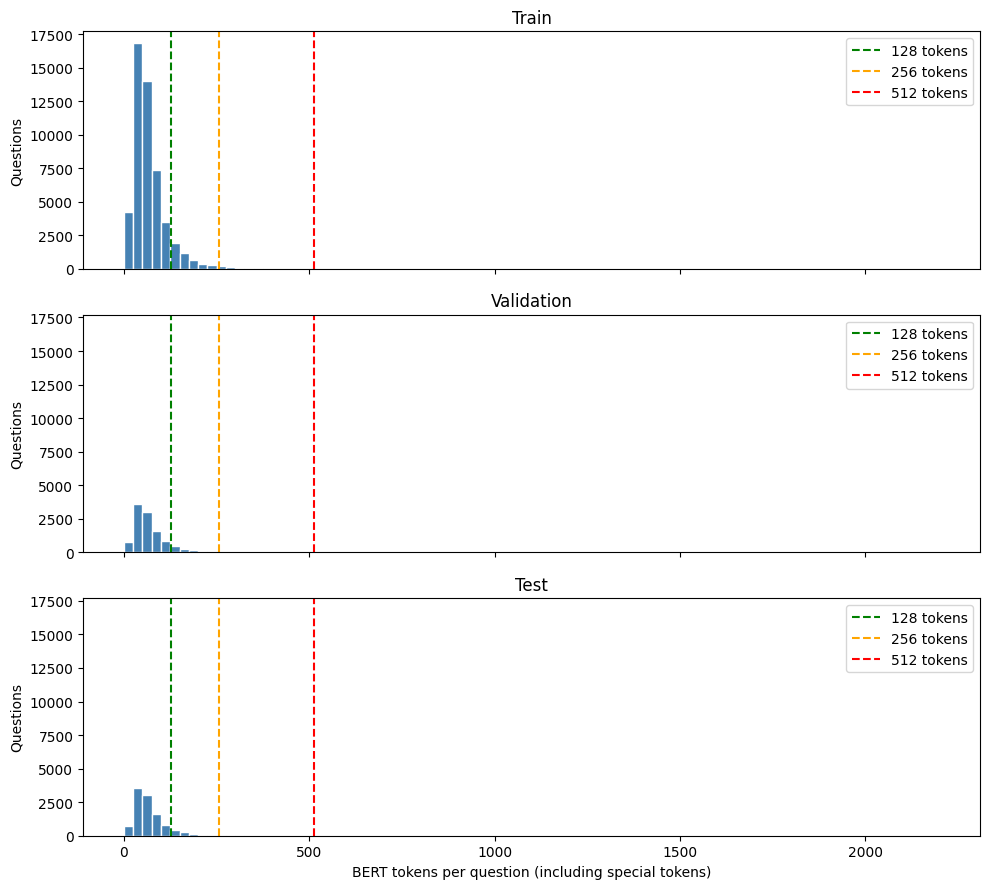

In [8]:
maximum = max(df["bert_token_count"].max() for df in splits.values())
bins = range(0, int(maximum) + 26, 25)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, (name, df) in zip(axes, splits.items()):
    ax.hist(df["bert_token_count"], bins=bins, color="steelblue", edgecolor="white")
    for limit, color in [(128, "green"), (256, "orange"), (512, "red")]:
        ax.axvline(limit, color=color, linestyle="--", label=f"{limit} tokens")
    ax.set_title(name.capitalize())
    ax.set_ylabel("Questions")
    ax.legend()
axes[-1].set_xlabel("BERT tokens per question (including special tokens)")
fig.tight_layout()
plt.show()


## Interpretation

Compare the truncation rates and the longest examples before choosing a training input length. These descriptive checks do not select a model or evaluate performance. Use training and validation data for later modeling decisions; keep the test split reserved for final model evaluation. No CSV files have been written by this notebook.